*1.导入所需库*

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

*2.数据加载*

In [2]:
dtype_dict = {
    'Order ID': 'str', 'SKU': 'str', 'ASIN': 'str', 'currency': 'str',
    'ship-city': 'str', 'ship-state': 'str', 'ship-country': 'str',
    'promotion-ids': 'str', 'B2B': 'str', 'fulfilled-by': 'str'
}
df_amazon = pd.read_csv('input\\Amazon Sale Report.csv',
                         index_col=0)
df_sale = pd.read_csv('input\\Sale Report.csv', 
                      index_col=0)
df_pl = pd.read_csv('input\\P & L March 2021.csv', 
                    index_col=0)
df_may = pd.read_csv('input\\May-2022.csv',
                      index_col=0)
df_IsR = pd.read_csv('input\\International sale Report.csv', 
                     index_col=0)

C:\Users\bccxz\AppData\Local\Temp\ipykernel_4588\683227795.py:6: DtypeWarning: Columns (23) have mixed types. Specify dtype option on import or set low_memory=False.
  df_amazon = pd.read_csv('input\\Amazon Sale Report.csv',
C:\Users\bccxz\AppData\Local\Temp\ipykernel_4588\683227795.py:12: DtypeWarning: Columns (7,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44) have mixed types. Specify dtype option on import or set low_memory=False.
  df_may = pd.read_csv('input\\May-2022.csv',


In [3]:
df_amazon.head()

,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,...,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Unnamed: 22
index,,,,,,,,,,,,,,,,,,,,,
0,405-8078784-5731545,04-30-22,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,S,...,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,NaN
1,171-9198151-1101146,04-30-22,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,3XL,...,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,NaN
2,404-0687676-7273146,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,XL,...,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,NaN
3,403-9615377-8133951,04-30-22,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,L,...,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,NaN
4,407-1069790-7240320,04-30-22,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,3XL,...,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,NaN


*3.分数据源预处理*

In [3]:
def preprocess_amazon(df):
    print("Amazon数据形状:", df.shape)
    print("Amazon缺失值统计:")
    print(df.isnull().sum().sort_values(ascending=False).head(10))
    if 'promotion-ids' in df.columns:
        df['promotion_count'] = df['promotion-ids'].apply(
            lambda x: len(str(x).split(',')) if pd.notnull(x) else 0
        )
    
    return df

def preprocess_sale(df):
    print("Sale Report数据形状:", df.shape)
    if 'Stock' in df.columns:
        df = df[df['Stock'] >= 0]
    return df

def preprocess_international(df):
    print("International数据形状:", df.shape)
    df.rename(columns={'GROSS AMT':'Amount','PCS':'Qty','DATE':'Date'}, inplace=True)
    return df

def preprocess_may(df):
    print("May-2022数据形状:", df.shape)
    essential_cols = ['Style', 'Net Amount', 'CP', 'MRP', 'GST', 
                     'Commission Charges', 'Shipping Charges', 'Other Charges']
    existing_cols = [col for col in essential_cols if col in df.columns]
    df = df[existing_cols].copy()
    column_mapping = {
        'Net Amount': 'Amount_M',
        'CP': 'Cost_Price',
        'MRP': 'MRP',
        'GST': 'GST',
        'Commission Charges': 'Commission',
        'Shipping Charges': 'Shipping',
        'Other Charges': 'Other_Charges'
    }
    rename_dict = {k: v for k, v in column_mapping.items() if k in df.columns}
    df.rename(columns=rename_dict, inplace=True)
    if 'Style' in df.columns:
        df['Style'] = df['Style'].astype(str).str.strip()
        df = df[df['Style'].notnull() & (df['Style'] != 'nan')]
    
    numeric_cols = ['Amount_M', 'Cost_Price', 'MRP', 'GST', 'Commission', 'Shipping', 'Other_Charges']
    for col in numeric_cols:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
            nan_count = df[col].isna().sum()
            if nan_count > 0:
                print(f"  列 {col}: 清理了 {nan_count} 个非数值数据（如#REF!）")
    
    print(f"预处理后May-2022记录数: {len(df)}")
    return df

df_amazon = preprocess_amazon(df_amazon)
df_sale = preprocess_sale(df_sale)
df_IsR = preprocess_international(df_IsR)
df_may = preprocess_may(df_may)

Amazon数据形状: (128975, 23)
Amazon缺失值统计:
fulfilled-by        89698
promotion-ids       49153
Unnamed: 22         49050
currency             7795
Amount               7795
Courier Status       6872
ship-city              33
ship-state             33
ship-postal-code       33
ship-country           33
dtype: int64
Sale Report数据形状: (9271, 6)
International数据形状: (37432, 9)
May-2022数据形状: (54505, 45)
  列 MRP: 清理了 54505 个非数值数据（如#REF!）
预处理后May-2022记录数: 54505


*4.数据合并*

In [4]:
# 与sale report合并
df_total = pd.merge(df_amazon, df_sale, 
                    how='inner', 
                    left_on='SKU', 
                    right_on='SKU Code', 
                    suffixes=['_A','_S'])
df_total.drop(columns = ['Category_S','Size_A','Unnamed: 22'],axis = 1,inplace = True)
df_total.rename(columns={'Size_S':'Size'}, inplace=True)

# 与International sale Report合并
df_total['source'] = 'Amazon'
df_IsR['source'] = 'International'
common_cols = list(set(df_total.columns).intersection(set(df_IsR.columns)))
df_total = df_total[common_cols]
df_IsR = df_IsR[common_cols]
df_total = pd.concat([df_total,df_IsR], 
                     axis = 0, 
                     ignore_index=True)



# 使用字典映射合并 May-2022 的价格特征
price_dict = {}
for _, row in df_may.iterrows():
    style = row.get('Style')
    if pd.notnull(style):
        price_dict[str(style)] = {
            'Amount_M': row.get('Amount_M'),
            'Cost_Price': row.get('Cost_Price'),
            'MRP': row.get('MRP'),
            'GST': row.get('GST'),
            'Commission': row.get('Commission'),
            'Shipping': row.get('Shipping'),
            'Other_Charges': row.get('Other_Charges')
        }
price_cols = ['Amount_M', 'Cost_Price', 'MRP', 'GST', 'Commission', 'Shipping', 'Other_Charges']
for col in price_cols:
    df_total[col] = np.nan

skus = df_total['SKU'].astype(str).values
matched_count = 0
for i, sku in enumerate(skus):
    if sku in price_dict:
        matched_count += 1
        price_data = price_dict[sku]
        for col in price_cols:
            if col in price_data:
                df_total.at[i, col] = price_data[col]

# 清理内存
del price_dict, skus


*5.移除高缺失率列*

In [5]:
missing_threshold = 0.9
cols_to_drop = [col for col in df_total.columns if df_total[col].isnull().mean() > missing_threshold]
if cols_to_drop:
    print(f"移除高缺失率列: {cols_to_drop}")
    df_total.drop(columns=cols_to_drop, inplace=True)

移除高缺失率列: ['MRP']


*6.数据清洗(清理异常字符串、inf值)*

In [6]:
all_cols = df_total.columns
for col in all_cols:
    if df_total[col].dtype == 'object':
        converted = pd.to_numeric(df_total[col], errors='coerce')
        nan_count = converted.isna().sum()
        if nan_count > 0 and nan_count < len(df_total):
            original_nan = df_total[col].isna().sum()
            new_nan = converted.isna().sum()
            if new_nan > original_nan:
                print(f"  列 '{col}': 清理了 {new_nan - original_nan} 个非数值数据（如#REF!）")
                df_total[col] = converted
    
    elif np.issubdtype(df_total[col].dtype, np.number):
        inf_mask = np.isinf(df_total[col])
        if inf_mask.any():
            print(f"  列 '{col}': 发现 {inf_mask.sum()} 个inf值，替换为NaN")
            df_total.loc[inf_mask, col] = np.nan

  列 'Size': 清理了 139905 个非数值数据（如#REF!）
  列 'Amount': 清理了 1 个非数值数据（如#REF!）
  列 'Qty': 清理了 1 个非数值数据（如#REF!）


*7. 缺失值填充*

In [7]:
#数值列用中位数填充,分类列用众数填充
numeric_cols = df_total.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df_total[col].isnull().sum() > 0:
        df_total[col] = df_total[col].fillna(df_total[col].median())
categorical_cols = df_total.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if df_total[col].isnull().sum() > 0:
        df_total[col] = df_total[col].fillna(df_total[col].mode()[0] if not df_total[col].mode().empty else 'Unknown')

*8. 利润计算*

In [8]:
def calculate_profit(row):
    try:
        # 收入
        revenue = row['Amount'] if pd.notnull(row['Amount']) else 0

        # 总成本
        cost_components = ['Cost_Price', 'GST', 'Commission', 'Shipping', 'Other_Charges']
        total_cost = 0
        for col in cost_components:
            if col in row and pd.notnull(row[col]):
                total_cost += row[col]
        
        # 计算利润
        profit = revenue - total_cost
        return profit
    except Exception as e:
        return np.nan


df_total['Profit'] = df_total.apply(calculate_profit, axis=1)

# 分析利润计算结果
profit_stats = {
    '总行数': len(df_total),
    '有效利润计算数': df_total['Profit'].notnull().sum(),
    '利润缺失数': df_total['Profit'].isnull().sum(),
    '平均利润': df_total['Profit'].mean() if df_total['Profit'].notnull().any() else np.nan,
    '最小利润': df_total['Profit'].min() if df_total['Profit'].notnull().any() else np.nan,
    '最大利润': df_total['Profit'].max() if df_total['Profit'].notnull().any() else np.nan
}

print("\n利润计算结果:")
for key, value in profit_stats.items():
    if pd.notnull(value):
        print(f"  {key}: {value:.2f}" if isinstance(value, float) else f"  {key}: {value}")

# 检查异常利润值
negative_profit = (df_total['Profit'] < 0).sum()
zero_profit = (df_total['Profit'] == 0).sum()
positive_profit = (df_total['Profit'] > 0).sum()

print(f"\n利润分布:")
print(f"  负利润: {negative_profit} 行 ({negative_profit/len(df_total)*100:.2f}%)")
print(f"  零利润: {zero_profit} 行 ({zero_profit/len(df_total)*100:.2f}%)")
print(f"  正利润: {positive_profit} 行 ({positive_profit/len(df_total)*100:.2f}%)")

# 显示前10行利润结果
print("\n前10行利润结果:")
print(df_total[['SKU', 'Amount', 'Cost_Price', 'Profit']].head(10))

# 删除y缺失的行
df_regression = df_total[df_total['Profit'].notnull()].copy()
print(f"回归分析可用数据: {len(df_regression)}/{len(df_total)} 行 ({len(df_regression)/len(df_total)*100:.1f}%)")


利润计算结果:
  总行数: 158701
  有效利润计算数: 158701
  利润缺失数: 0
  平均利润: 595.28
  最小利润: -475.01
  最大利润: 9723.10

利润分布:
  负利润: 10226 行 (6.44%)
  零利润: 0 行 (0.00%)
  正利润: 148475 行 (93.56%)

前10行利润结果:
               SKU  Amount  Cost_Price  Profit
0   SET389-KR-NP-S  647.62         0.0  561.61
1  JNE3781-KR-XXXL  406.00         0.0  416.23
2    JNE3371-KR-XL  329.00         0.0  307.10
3       J0341-DR-L  753.33         0.0  706.53
4  JNE3671-TU-XXXL  574.00         0.0  539.56
5  SET264-KR-NP-XL  824.00         0.0  682.86
6      J0095-SET-L  653.00         0.0  579.01
7     JNE3405-KR-S  399.00         0.0  399.88
8   JNE3461-KR-XXL  363.00         0.0  370.59
9    JNE3500-KR-XS  364.00         0.0  342.10
回归分析可用数据: 158701/158701 行 (100.0%)


*9. 目标变量平滑化（对数变换）*

In [9]:
# # 修复1：在平滑化判断部分，使用正确的变量
# print("\n=== 平滑化必要性判断 ===")

# # 关键判断指标 - 使用df_regression['Profit']而不是未定义的profit_data
# profit_data = df_regression['Profit'].copy()  # 添加这行定义
# skewness = profit_data.skew()
# kurtosis_value = profit_data.kurtosis()
# mean = profit_data.mean()
# std = profit_data.std()
# median = profit_data.median()

# # 修复2：改进数据清洗逻辑，避免类型转换错误
# print("清理数值列中的异常值...")

# # 更安全的数据类型检查方法
# for col in df_total.columns:
#     # 只对看起来可能是数值的列进行转换
#     if df_total[col].dtype == 'object':
#         # 先检查列中是否大部分是数值
#         sample_values = df_total[col].dropna().head(100)
#         if len(sample_values) > 0:
#             # 检查是否包含数值字符
#             numeric_count = sum(str(val).replace('.', '').replace('-', '').isdigit() 
#                               for val in sample_values if pd.notnull(val))
            
#             if numeric_count / len(sample_values) > 0.5:  # 超过50%看起来像数值
#                 try:
#                     converted = pd.to_numeric(df_total[col], errors='coerce')
#                     original_nan = df_total[col].isna().sum()
#                     new_nan = converted.isna().sum()
#                     if new_nan > original_nan:
#                         print(f"  列 '{col}': 清理了 {new_nan - original_nan} 个非数值数据")
#                         df_total[col] = converted
#                 except Exception as e:
#                     print(f"  列 '{col}' 转换失败: {e}")
#                     continue



检测到负利润，平移 476.01 后取对数


C:\Users\bccxz\AppData\Local\Temp\ipykernel_17672\3490649378.py:31: UserWarning: Glyph 21033 (\N{CJK UNIFIED IDEOGRAPH-5229}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\bccxz\AppData\Local\Temp\ipykernel_17672\3490649378.py:31: UserWarning: Glyph 28070 (\N{CJK UNIFIED IDEOGRAPH-6DA6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\bccxz\AppData\Local\Temp\ipykernel_17672\3490649378.py:31: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\bccxz\AppData\Local\Temp\ipykernel_17672\3490649378.py:31: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\bccxz\AppData\Local\Temp\ipykernel_17672\3490649378.py:31: UserWarning: Glyph 21407 (\N{CJK UNIFIED IDEOGRAPH-539F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\bccxz\AppData\Local\Temp\ipykernel_17672\3490649378.py:31: UserWarning: Glyph 22987 (\

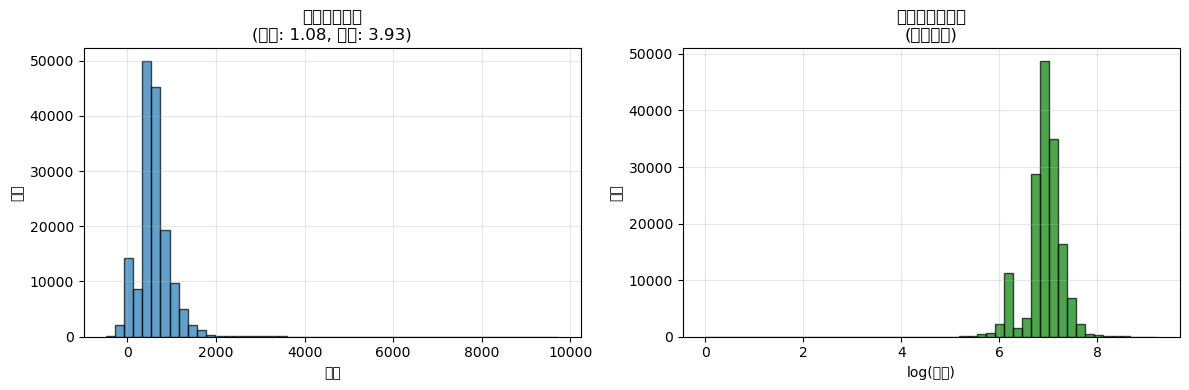


=== 平滑前后对比 ===
原始利润 - 均值: 595.28, 标准差: 379.92
平滑后利润 - 均值: 6.92, 标准差: 0.36


In [10]:
original_profit = df_regression['Profit'].copy()

min_profit = original_profit.min()
if min_profit < 0:
    shift_value = 1 - min_profit
    smoothed_profit = np.log(original_profit + shift_value)
    print(f"检测到负利润，平移 {shift_value:.2f} 后取对数")
else: 
    smoothed_profit = np.log(original_profit + 1)  # +1避免log(0)
    print("利润均为非负，使用 log(Profit + 1)")

df_regression['Profit_smoothed'] = smoothed_profit

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 绘制平滑前后对比图
# 原始利润分布
axes[0].hist(original_profit, bins=50, edgecolor='black', alpha=0.7)
axes[0].set_title('原始利润分布\n(偏度: 1.08, 峰度: 3.93)')
axes[0].set_xlabel('利润')
axes[0].set_ylabel('频数')
axes[0].grid(True, alpha=0.3)

# 平滑后利润分布
axes[1].hist(smoothed_profit, bins=50, edgecolor='black', alpha=0.7, color='green')
axes[1].set_title('平滑后利润分布\n(对数变换)')
axes[1].set_xlabel('log(利润)')
axes[1].set_ylabel('频数')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== 平滑前后对比 ===")
print(f"原始利润 - 均值: {original_profit.mean():.2f}, 标准差: {original_profit.std():.2f}")
print(f"平滑后利润 - 均值: {smoothed_profit.mean():.2f}, 标准差: {smoothed_profit.std():.2f}")


*10. 数据过滤与特征工程*

In [11]:
# df_regression_dummy = pd.get_dummies(df_regression)
# df_regression_dummy.head()

In [12]:
# 过滤无效日期
df_regression = df_regression[df_regression['Date'] != 'SKU'].reset_index(drop=True)
df_regression = df_regression[df_regression['Date'].astype(str).str.match(r'^\d')]

# 1. 日期处理
df_regression['Date'] = pd.to_datetime(df_regression['Date'])
df_regression['year'] = df_regression['Date'].dt.year
df_regression['month'] = df_regression['Date'].dt.month
df_regression['day'] = df_regression['Date'].dt.day


# 分类列 (one-hot前): ['source', 'Size', 'SKU', 'Style']
# 数值列: ['Amount', 'Qty', 'Amount_M', 'Cost_Price', 'MRP', 'GST', 'Commission', 'Shipping', 'Other_Charges', 'Profit', 'Profit_smoothed']
# 日期列: ['Date']期列: {date_cols}")

# 2. 分类列处理策略
print("分类列处理策略:")

# 低基数分类：直接one-hot
low_cardinality = ['source', 'Size']

# 高基数分类：使用频率编码或目标编码
high_cardinality = ['SKU', 'Style']

# 3. one-hot
df_regression = pd.get_dummies(df_regression, columns=low_cardinality, drop_first=True)

# 4. 频率编码
for col in high_cardinality:
    freq = df_regression[col].value_counts()
    df_regression[f'{col}_freq'] = df_regression[col].map(freq)
    print(f"{col} 唯一值数量: {df_regression[col].nunique()}")

# 5. 删除原始的高基数分类列
df_regression_dummy = df_regression.drop(columns=high_cardinality)

print(f"\n最终数据形状: {df_regression_dummy.shape}")
print(f"总列数: {len(df_regression_dummy.columns)}")


分类列处理策略:
SKU 唯一值数量: 7514
Style 唯一值数量: 1384

最终数据形状: (139905, 17)
总列数: 17


C:\Users\bccxz\AppData\Local\Temp\ipykernel_17672\422388046.py:6: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_regression['Date'] = pd.to_datetime(df_regression['Date'])


*11. 划分 X 和 y*

In [13]:
y = df_regression_dummy['Profit_smoothed'].copy()
X = df_regression_dummy.drop(columns=['Profit_smoothed', 'Profit', 'Date']).copy()

print(f"X形状: {X.shape}")
print(f"y形状: {y.shape}")
print(f"目标变量统计: 均值={y.mean():.4f}, 标准差={y.std():.4f}")

X形状: (139905, 14)
y形状: (139905,)
目标变量统计: 均值=7.0039, 标准差=0.2642


*12. 特征归一化（对数变换)*

In [14]:
# 2. 识别非one-hot数值列（需要归一化的列）
one_hot_prefixes = ['source_', 'Size_']
one_hot_cols = [col for col in X.columns if any(col.startswith(prefix) for prefix in one_hot_prefixes)]
num_cols = X.columns[X.dtypes != 'object']
cols_to_normalize = [col for col in num_cols if col not in one_hot_cols]

print(f"\n需要归一化的列 ({len(cols_to_normalize)}个):")
for col in cols_to_normalize:
    print(f"  - {col}: 范围 [{X[col].min():.2f}, {X[col].max():.2f}], 均值={X[col].mean():.2f}, 标准差={X[col].std():.2f}")


#使用对数变换进行归一化
print("\n=== 使用对数变换进行归一化 ===")
X_normalized = X.copy()

if cols_to_normalize:
    X_original = X[cols_to_normalize].copy()
    for col in cols_to_normalize:
        min_val = X[col].min()
        if min_val <= 0:
            shift_value = 1 - min_val
            X_normalized[col] = np.log1p(X[col] + shift_value)
            print(f"  列 '{col}': 检测到最小值 {min_val:.2f}，平移 {shift_value:.2f} 后取对数")
        else:
            X_normalized[col] = np.log1p(X[col])
    
    print(f"对数变换后统计:")
    for col in cols_to_normalize[:5]: 
        print(f"  - {col}: 范围 [{X_normalized[col].min():.4f}, {X_normalized[col].max():.4f}], 均值={X_normalized[col].mean():.4f}, 标准差={X_normalized[col].std():.4f}")
    if len(cols_to_normalize) > 5:
        print(f"  ... 共{len(cols_to_normalize)}列已进行对数变换")
else:
    print("\n没有需要归一化的列")

# 4. 保存归一化后的数据
df_X_normalized = X_normalized.copy()
df_y = y.copy()

print(f"  - 特征数据形状: {df_X_normalized.shape}")
print(f"  - 目标变量形状: {df_y.shape}")
print(f"  - 特征列数: {len(df_X_normalized.columns)}")


# 保存变换信息用于后续预测
import joblib
transform_info = {
    'cols_to_normalize': cols_to_normalize,
    'transform_type': 'log1p'
}
transform_filename = 'log_transform_info.save'
joblib.dump(transform_info, transform_filename)



需要归一化的列 (13个):
  - Amount: 范围 [0.00, 9745.00], 均值=674.79, 标准差=346.78
  - Qty: 范围 [0.00, 15.00], 均值=0.96, 标准差=0.47
  - Amount_M: 范围 [-3462.00, 2648.00], 均值=-736.73, 标准差=776.64
  - Cost_Price: 范围 [0.00, 0.00], 均值=0.00, 标准差=0.00
  - GST: 范围 [-164.86, 283.71], 均值=-29.98, 标准差=53.78
  - Commission: 范围 [-593.68, 776.18], 均值=165.18, 标准差=174.12
  - Shipping: 范围 [-182.60, -53.10], 均值=-170.03, 标准差=32.88
  - Other_Charges: 范围 [-82.60, 59.00], 均值=44.38, 标准差=40.06
  - year: 范围 [2004.00, 2022.00], 均值=2015.63, 标准差=8.18
  - month: 范围 [1.00, 12.00], 均值=5.60, 标准差=2.66
  - day: 范围 [1.00, 31.00], 均值=20.76, 标准差=5.34
  - SKU_freq: 范围 [1.00, 2191.00], 均值=116.78, 标准差=284.77
  - Style_freq: 范围 [1.00, 3724.00], 均值=522.03, 标准差=733.12

=== 使用对数变换进行归一化 ===
  列 'Amount': 检测到最小值 0.00，平移 1.00 后取对数
  列 'Qty': 检测到最小值 0.00，平移 1.00 后取对数
  列 'Amount_M': 检测到最小值 -3462.00，平移 3463.00 后取对数
  列 'Cost_Price': 检测到最小值 0.00，平移 1.00 后取对数
  列 'GST': 检测到最小值 -164.86，平移 165.86 后取对数
  列 'Commission': 检测到最小值 -593.68，平移 594.68 后取对数
  列 'Sh

['log_transform_info.save']

In [15]:
df_X_normalized.head()

,Amount,Qty,Amount_M,Cost_Price,GST,Commission,Shipping,Other_Charges,year,month,day,source_International,SKU_freq,Style_freq
0,6.476388,0.693147,7.730614,0.693147,4.703567,6.759035,0.693147,4.967032,7.612337,1.609438,3.433987,False,3.663562,5.613128
1,6.011267,1.098612,7.945201,0.693147,4.914785,6.606137,0.693147,4.967032,7.612337,1.609438,3.433987,False,4.700480,6.298949
2,5.802118,1.098612,7.878534,0.693147,4.849057,6.659832,0.693147,4.967032,7.612337,1.609438,3.433987,False,2.772589,4.454347
3,6.627155,0.693147,7.823646,0.693147,4.795046,6.699537,0.693147,4.967032,7.612337,1.609438,3.433987,False,5.697093,7.404888
4,6.356108,1.098612,7.851272,0.693147,4.822215,6.680026,0.693147,4.967032,7.612337,1.609438,3.433987,False,2.995732,4.709530


*13. 模型训练 - 岭回归*

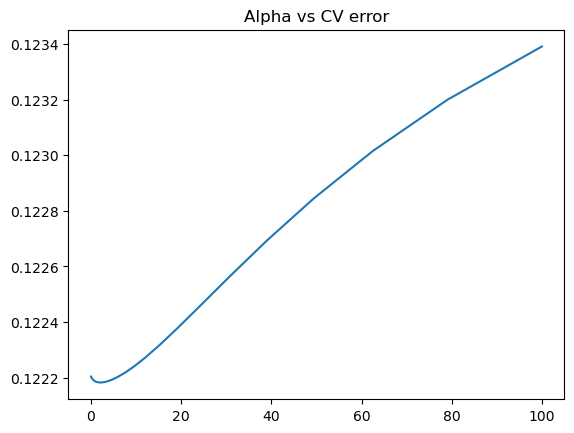

Best alpha: 1.8420699693267164
Best Score: 0.12218225714905737


In [18]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_score

X_train = df_X_normalized.values
Y_train = df_y.values

alphas = np.logspace(-3,2,50)
test_scores = list()
for alpha in alphas:
    clf = Ridge(alpha)
    test_score = np.sqrt(-cross_val_score(clf, X_train, Y_train, cv=10, scoring='neg_mean_squared_error'))
    test_scores.append(np.mean(test_score))  

%matplotlib inline
plt.plot(alphas,test_scores)
plt.title('Alpha vs CV error')
plt.show()

best_alpha = alphas[np.argmin(test_scores)]
print("Best alpha:", best_alpha)
print("Best Score:", np.min(test_scores))

*14. 模型训练 - 随机森林*

=== 取消对数变换的随机森林模型 ===
X形状: (139905, 14)
y形状: (139905,)
目标变量统计: 均值=665.25, 标准差=343.88
利润范围: [-475.01, 9723.10]
负利润数量: 1627 (1.16%)
零利润数量: 0 (0.00%)
正利润数量: 138278 (98.84%)


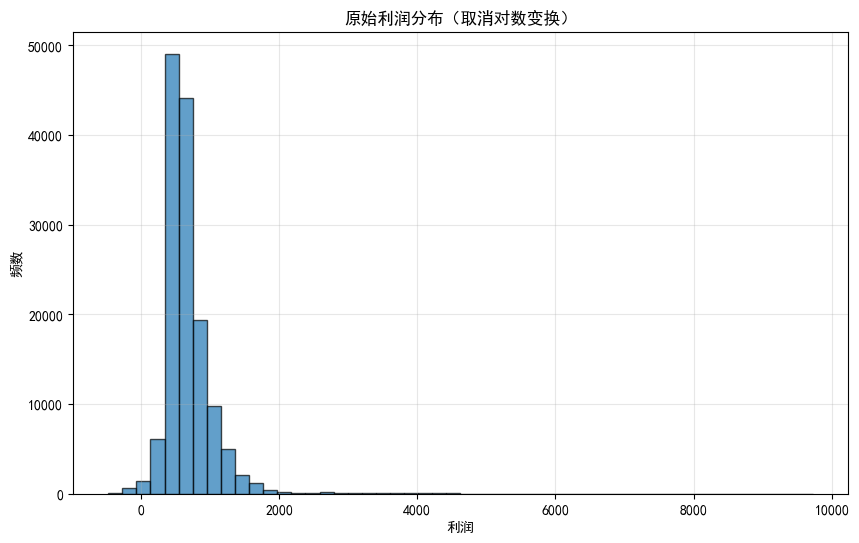


=== 随机森林模型训练（使用原始利润） ===


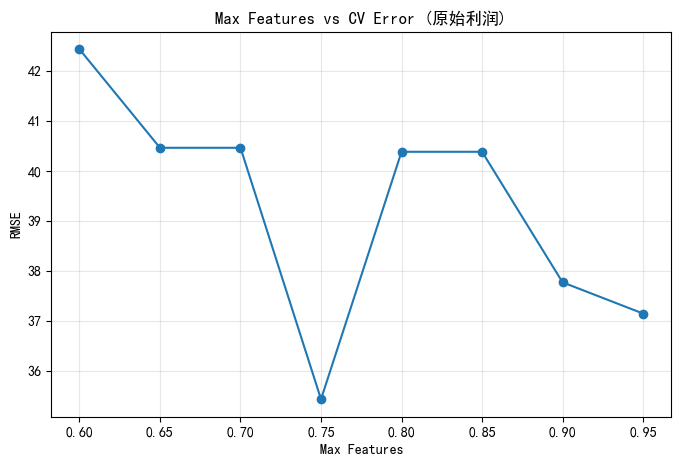

初步最佳 max_features: 0.75


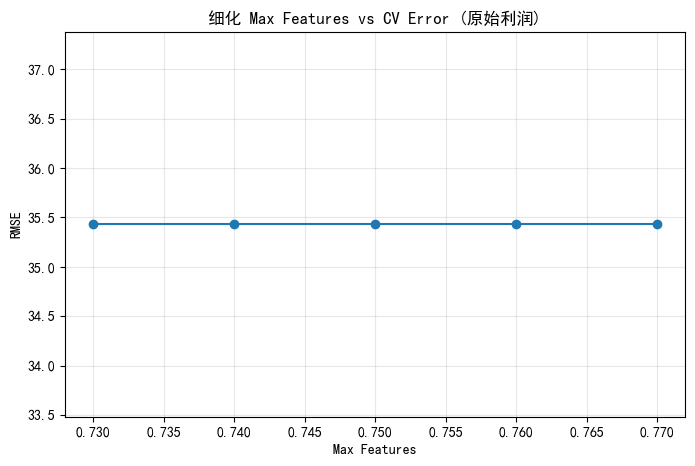

细化后最佳 max_features: 0.73

=== 调整 min_samples_leaf ===
leaf= 1 | train RMSE=3.28 | val RMSE=9.63
leaf= 2 | train RMSE=5.29 | val RMSE=10.65
leaf= 3 | train RMSE=8.21 | val RMSE=12.16
leaf= 5 | train RMSE=12.60 | val RMSE=15.72
leaf=10 | train RMSE=20.35 | val RMSE=22.23
leaf=20 | train RMSE=27.29 | val RMSE=29.83
leaf=50 | train RMSE=37.67 | val RMSE=39.75

最佳 min_samples_leaf = 1

最终模型性能:
训练集 RMSE: 3.28
验证集 RMSE: 9.63
存在过拟合，可继续增大 leaf 或减少 max_features

5折交叉验证 RMSE: 58.17

=== 特征重要性分析（原始利润） ===
特征重要性排序:
 1. Amount              : 0.763480
 2. Commission          : 0.085892
 3. Qty                 : 0.077254
 4. Amount_M            : 0.031287
 5. GST                 : 0.031012
 6. Other_Charges       : 0.004457
 7. Style_freq          : 0.002598
 8. source_International: 0.001380
 9. Shipping            : 0.001154
10. month               : 0.000631
11. SKU_freq            : 0.000529
12. day                 : 0.000254
13. year                : 0.000072
14. Cost_Price          : 0.000000


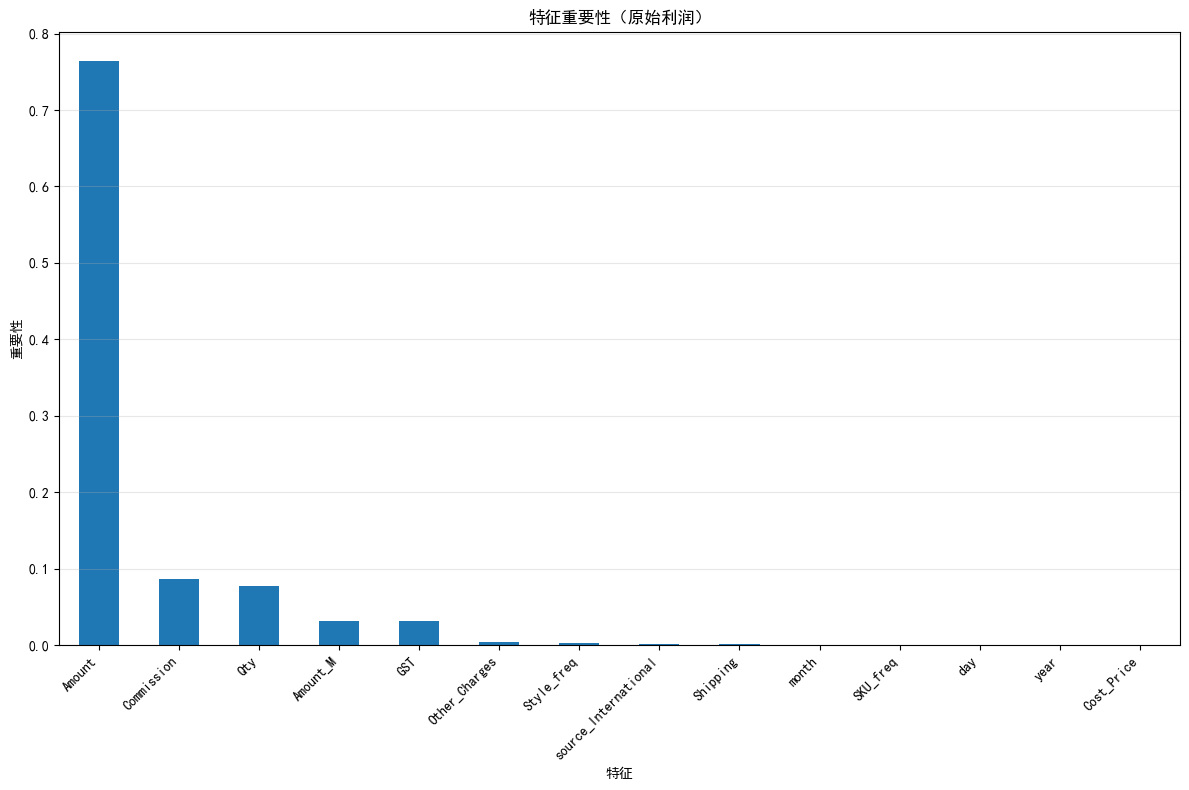


前7个重要特征: ['Amount', 'Commission', 'Qty', 'Amount_M', 'GST', 'Other_Charges', 'Style_freq']


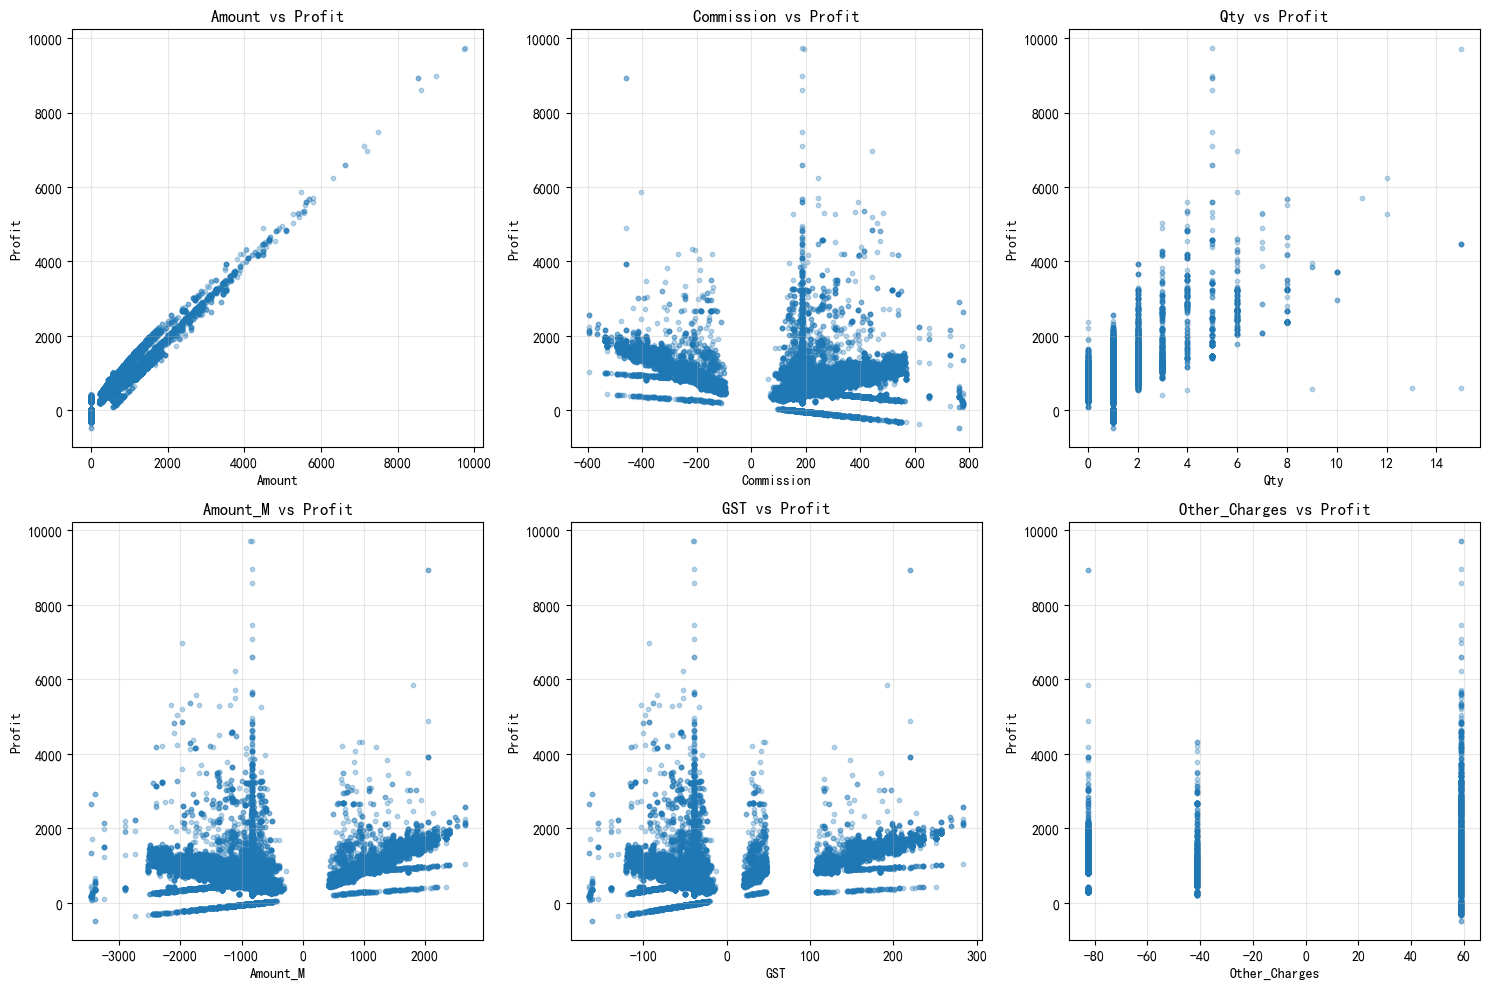


=== 特征相关性热力图 ===


NameError: name 'sns' is not defined

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, train_test_split, RepeatedKFold, GridSearchCV
from sklearn.metrics import mean_squared_error

y_original = df_regression_dummy['Profit'].copy()  # 使用原始利润，而不是Profit_smoothed
X_original = df_regression_dummy.drop(columns=['Profit_smoothed', 'Profit', 'Date']).copy()

print("=== 取消对数变换的随机森林模型 ===")
print(f"X形状: {X_original.shape}")
print(f"y形状: {y_original.shape}")
print(f"目标变量统计: 均值={y_original.mean():.2f}, 标准差={y_original.std():.2f}")
print(f"利润范围: [{y_original.min():.2f}, {y_original.max():.2f}]")
print(f"负利润数量: {(y_original < 0).sum()} ({((y_original < 0).sum()/len(y_original))*100:.2f}%)")
print(f"零利润数量: {(y_original == 0).sum()} ({((y_original == 0).sum()/len(y_original))*100:.2f}%)")
print(f"正利润数量: {(y_original > 0).sum()} ({((y_original > 0).sum()/len(y_original))*100:.2f}%)")

# 绘制原始利润分布
plt.figure(figsize=(10, 6))
plt.hist(y_original, bins=50, edgecolor='black', alpha=0.7)
plt.title('原始利润分布（取消对数变换）')
plt.xlabel('利润')
plt.ylabel('频数')
plt.grid(True, alpha=0.3)
plt.show()

# 转换为numpy数组用于模型训练
X_train_original = X_original.values
Y_train_original = y_original.values

print("\n=== 随机森林模型训练（使用原始利润） ===")

# 初步选择 max_features
max_features = [.6, .65, .7, .75, .8, .85, .9, .95]
test_scores = list()

for max_feature in max_features:
    clf = RandomForestRegressor(n_estimators=100, max_features=max_feature,
                               random_state=42)
    test_score = np.sqrt(-cross_val_score(clf, X_train_original, Y_train_original, cv=3,
                                         scoring='neg_mean_squared_error'))
    test_scores.append(np.mean(test_score))

plt.figure(figsize=(8, 5))
plt.plot(max_features, test_scores, marker='o')
plt.title("Max Features vs CV Error (原始利润)")
plt.xlabel("Max Features")
plt.ylabel("RMSE")
plt.grid(True, alpha=0.3)
plt.show()

best_idx = np.argmin(test_scores)
best_max_features = max_features[best_idx]
print(f"初步最佳 max_features: {best_max_features}")

# 细化 max_features 搜索
max_features_refined = [best_max_features-0.02, best_max_features-0.01, best_max_features, 
                       best_max_features+0.01, best_max_features+0.02]
max_features_refined = [round(mf, 2) for mf in max_features_refined if 0 < mf < 1]

test_scores_refined = list()
for max_feature in max_features_refined:
    clf = RandomForestRegressor(n_estimators=100, max_features=max_feature,
                               random_state=42)
    test_score = np.sqrt(-cross_val_score(clf, X_train_original, Y_train_original, cv=3,
                                         scoring='neg_mean_squared_error'))
    test_scores_refined.append(np.mean(test_score))

if len(max_features_refined) > 1:
    plt.figure(figsize=(8, 5))
    plt.plot(max_features_refined, test_scores_refined, marker='o')
    plt.title("细化 Max Features vs CV Error (原始利润)")
    plt.xlabel("Max Features")
    plt.ylabel("RMSE")
    plt.grid(True, alpha=0.3)
    plt.show()

    best_idx_refined = np.argmin(test_scores_refined)
    best_max_features_refined = max_features_refined[best_idx_refined]
    print(f"细化后最佳 max_features: {best_max_features_refined}")
else:
    best_max_features_refined = best_max_features

# 调整 min_samples_leaf
X_tr, X_val, y_tr, y_val = train_test_split(X_train_original, Y_train_original, test_size=0.2, random_state=42)

leaf_candidates = [1, 2, 3, 5, 10, 20, 50]
val_errors = []
train_errors = []

print("\n=== 调整 min_samples_leaf ===")
for leaf in leaf_candidates:
    rf = RandomForestRegressor(n_estimators=100, max_features=best_max_features_refined,
                               min_samples_leaf=leaf, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    train_rmse = np.sqrt(mean_squared_error(y_tr, rf.predict(X_tr)))
    val_rmse = np.sqrt(mean_squared_error(y_val, rf.predict(X_val)))
    train_errors.append(train_rmse)
    val_errors.append(val_rmse)
    print(f"leaf={leaf:2d} | train RMSE={train_rmse:.2f} | val RMSE={val_rmse:.2f}")

best_leaf = leaf_candidates[np.argmin(val_errors)]
print(f"\n最佳 min_samples_leaf = {best_leaf}")

# 训练最终模型
best_rf = RandomForestRegressor(n_estimators=100, max_features=best_max_features_refined,
                                min_samples_leaf=best_leaf, random_state=42, n_jobs=-1)
best_rf.fit(X_tr, y_tr)
final_train_rmse = np.sqrt(mean_squared_error(y_tr, best_rf.predict(X_tr)))
final_val_rmse = np.sqrt(mean_squared_error(y_val, best_rf.predict(X_val)))
print(f"\n最终模型性能:")
print(f"训练集 RMSE: {final_train_rmse:.2f}")
print(f"验证集 RMSE: {final_val_rmse:.2f}")

if final_val_rmse > final_train_rmse * 1.1:
    print("存在过拟合，可继续增大 leaf 或减少 max_features")
else:
    print("泛化良好")

# 5折交叉验证
scores = cross_val_score(best_rf, X_train_original, Y_train_original, cv=5,
                         scoring='neg_mean_squared_error', n_jobs=-1)
rmse_cv = np.sqrt(-scores.mean())
print(f"\n5折交叉验证 RMSE: {rmse_cv:.2f}")

# 特征重要性分析
print("\n=== 特征重要性分析（原始利润） ===")
best_rf.fit(X_train_original, Y_train_original)
importances = pd.Series(best_rf.feature_importances_, index=X_original.columns).sort_values(ascending=False)

print("特征重要性排序:")
for i, (feature, importance) in enumerate(importances.items()):
    print(f"{i+1:2d}. {feature:20s}: {importance:.6f}")

# 绘制特征重要性条形图
plt.figure(figsize=(12, 8))
importances.plot(kind='bar')
plt.title('特征重要性（原始利润）')
plt.xlabel('特征')
plt.ylabel('重要性')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.grid(True, alpha=0.3, axis='y')
plt.show()

# 绘制前7个重要特征的散点图
important_features = importances.head(7).index.tolist()
print(f"\n前7个重要特征: {important_features}")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, feature in enumerate(important_features[:6]):
    axes[i].scatter(X_original[feature], y_original, alpha=0.3, s=10)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel('Profit')
    axes[i].set_title(f'{feature} vs Profit')
    axes[i].grid(True, alpha=0.3)

# 隐藏多余的子图
for i in range(len(important_features[:6]), 6):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# 绘制特征相关性热力图
print("\n=== 特征相关性热力图 ===")
numeric_features = X_original.select_dtypes(include=[np.number]).columns
correlation_matrix = X_original[numeric_features].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title('特征间相关性热力图（原始数据）', fontsize=16)
plt.tight_layout()
plt.show()

# 打印相关性最高的特征对
print("相关性最高的特征对：")
corr_pairs = correlation_matrix.unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 0.99]  # 去除自相关
print(corr_pairs.head(10))

print("\n=== 模型总结 ===")
print(f"1. 使用原始利润作为目标变量（未进行对数变换）")
print(f"2. 最佳参数: max_features={best_max_features_refined}, min_samples_leaf={best_leaf}")
print(f"3. 模型性能: 5折CV RMSE = {rmse_cv:.2f}")
print(f"4. 最重要的特征: {importances.index[0]} (重要性: {importances.iloc[0]:.4f})")
print(f"5. 前5个重要特征占总重要性的: {importances.head(5).sum()*100:.1f}%")

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, train_test_split, RepeatedKFold, GridSearchCV
from sklearn.metrics import mean_squared_error

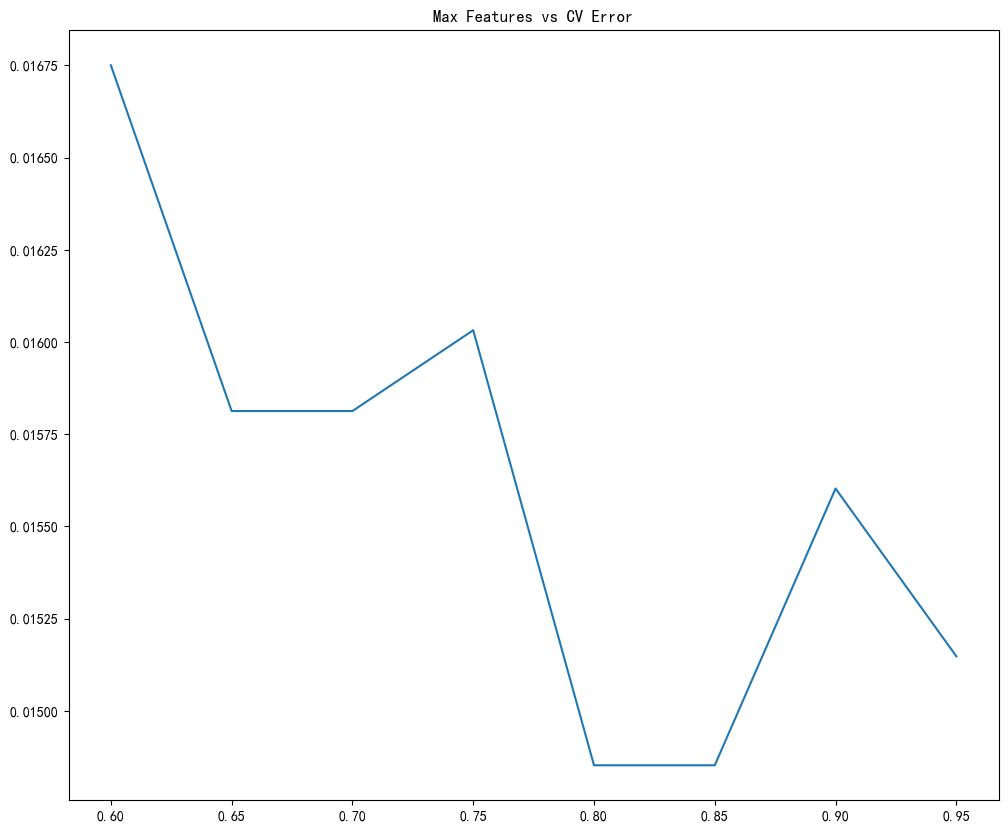

初步最佳 max_features: 0.8


In [ ]:
# 初步选择 max_features
max_features = [.6, .65, .7, .75, .8, .85, .9, .95]
test_scores = list()

for max_feature in max_features:
    clf = RandomForestRegressor(n_estimators=100, max_features=max_feature,
                               random_state=42)
    test_score = np.sqrt(-cross_val_score(clf, X_train, Y_train, cv=3,
                                         scoring='neg_mean_squared_error'))
    test_scores.append(np.mean(test_score))

plt.plot(max_features, test_scores)
plt.title("Max Features vs CV Error")
plt.show()
best_idx = np.argmin(test_scores)          # test_scores 是之前循环得到的列表
best_max_features = max_features[best_idx]
print("初步最佳 max_features:", best_max_features)

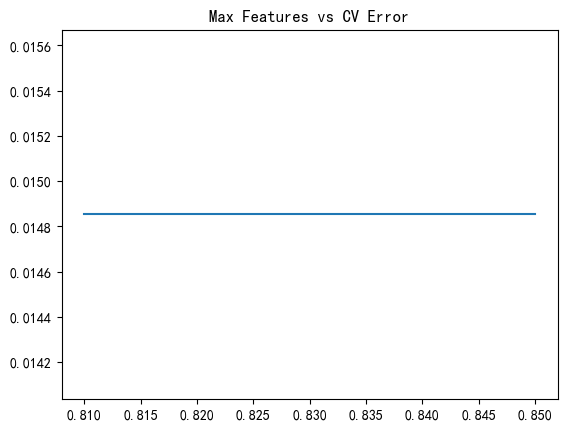

细化后最佳 max_features: 0.81


In [ ]:
# 细化 max_features 搜索
max_features = [.81, .82, .83, .84, .85]
test_scores = list()

for max_feature in max_features:
    clf = RandomForestRegressor(n_estimators=100, max_features=max_feature,
                               random_state=42)
    
    test_score = np.sqrt(-cross_val_score(clf, X_train, Y_train, cv=3,
                                         scoring='neg_mean_squared_error'))
    test_scores.append(np.mean(test_score))

plt.plot(max_features, test_scores)
plt.title("Max Features vs CV Error")
plt.show()

best_idx = np.argmin(test_scores)        
best_max_features = max_features[best_idx]
print("细化后最佳 max_features:", best_max_features)

In [ ]:
# from sklearn.ensemble import RandomForestRegressor
# from sklearn.model_selection import cross_val_score, RepeatedKFold
# import numpy as np

# # ========== 步骤2：重复交叉验证对比 0.75 与 0.81 ==========
# rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=42)

# def get_cv_error(max_feat):
#     rf = RandomForestRegressor(n_estimators=100, max_features=max_feat, random_state=42, n_jobs=-1)
#     neg_mse = cross_val_score(rf, X_train, Y_train, cv=rkf, scoring='neg_mean_squared_error', n_jobs=-1)
#     return np.sqrt(-neg_mse.mean())

# err_075 = get_cv_error(0.75)
# err_081 = get_cv_error(0.81)
# print(f"RMSE (5x10-fold CV): max_features=0.75 -> {err_075:.5f}, 0.81 -> {err_081:.5f}")

# # ========== 步骤3：联合调优 min_samples_leaf ==========
# leaf_values = [1, 2, 3, 5, 10]
# scores = []
# for leaf in leaf_values:
#     rf = RandomForestRegressor(n_estimators=100, max_features=0.81,
#                                min_samples_leaf=leaf, random_state=42, n_jobs=-1)
#     neg_mse = cross_val_score(rf, X_train, Y_train, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
#     rmse = np.sqrt(-neg_mse.mean())
#     scores.append(rmse)
#     print(f"min_samples_leaf={leaf:2d} -> RMSE = {rmse:.5f}")
# best_leaf = leaf_values[np.argmin(scores)]
# print(f"最佳 min_samples_leaf = {best_leaf}")

# # ========== 步骤4：训练集 vs 验证集误差（过拟合检查） ==========
# from sklearn.model_selection import train_test_split
# X_tr, X_val, y_tr, y_val = train_test_split(X_train, Y_train, test_size=0.2, random_state=42)
# rf = RandomForestRegressor(n_estimators=100, max_features=0.81, min_samples_leaf=best_leaf, random_state=42, n_jobs=-1)
# rf.fit(X_tr, y_tr)

# from sklearn.metrics import mean_squared_error
# train_rmse = np.sqrt(mean_squared_error(y_tr, rf.predict(X_tr)))
# val_rmse   = np.sqrt(mean_squared_error(y_val, rf.predict(X_val)))
# print(f"过拟合检查: 训练集 RMSE = {train_rmse:.5f}, 验证集 RMSE = {val_rmse:.5f}")
# if val_rmse > train_rmse * 1.05:
#     print("⚠️ 存在轻微过拟合，可增大 min_samples_leaf")
# else:
#     print("✅ 泛化良好，无明显过拟合")



In [ ]:
# 调整 min_samples_leaf
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# 固定 max_features=0.75
X_tr, X_val, y_tr, y_val = train_test_split(X_train, Y_train, test_size=0.2, random_state=42)

leaf_candidates = [1, 2, 3, 5, 10, 20, 50]
val_errors = []
train_errors = []

for leaf in leaf_candidates:
    rf = RandomForestRegressor(n_estimators=100, max_features=0.75,
                               min_samples_leaf=leaf, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    train_rmse = np.sqrt(mean_squared_error(y_tr, rf.predict(X_tr)))
    val_rmse = np.sqrt(mean_squared_error(y_val, rf.predict(X_val)))
    train_errors.append(train_rmse)
    val_errors.append(val_rmse)
    print(f"leaf={leaf:2d} | train RMSE={train_rmse:.5f} | val RMSE={val_rmse:.5f}")

best_leaf = leaf_candidates[np.argmin(val_errors)]
print(f"\n最佳 min_samples_leaf = {best_leaf}")

leaf= 1 | train RMSE=0.00094 | val RMSE=0.04203
leaf= 2 | train RMSE=0.00160 | val RMSE=0.04251
leaf= 3 | train RMSE=0.00224 | val RMSE=0.04295
leaf= 5 | train RMSE=0.00328 | val RMSE=0.04307
leaf=10 | train RMSE=0.00512 | val RMSE=0.04383
leaf=20 | train RMSE=0.00763 | val RMSE=0.04458
leaf=50 | train RMSE=0.01166 | val RMSE=0.04619

最佳 min_samples_leaf = 1


In [ ]:
best_rf = RandomForestRegressor(n_estimators=100, max_features=0.75,
                                min_samples_leaf=best_leaf, random_state=42)
best_rf.fit(X_tr, y_tr)
final_train_rmse = np.sqrt(mean_squared_error(y_tr, best_rf.predict(X_tr)))
final_val_rmse = np.sqrt(mean_squared_error(y_val, best_rf.predict(X_val)))
print(f"最终模型：train RMSE={final_train_rmse:.5f}, val RMSE={final_val_rmse:.5f}")
if final_val_rmse > final_train_rmse * 1.1:
    print("仍有过拟合，可继续增大 leaf 或减少 max_features")
else:
    print("泛化良好")

最终模型：train RMSE=0.00094, val RMSE=0.04203
仍有过拟合，可继续增大 leaf 或减少 max_features


In [ ]:
# 再次调整 max_features
max_feat_candidates = [0.3, 0.4, 0.5, 0.6, 0.7]
val_errors = []
train_errors = []

for mf in max_feat_candidates:
    rf = RandomForestRegressor(n_estimators=100, max_features=mf,
                               min_samples_leaf=1, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    train_rmse = np.sqrt(mean_squared_error(y_tr, rf.predict(X_tr)))
    val_rmse = np.sqrt(mean_squared_error(y_val, rf.predict(X_val)))
    train_errors.append(train_rmse)
    val_errors.append(val_rmse)
    print(f"max_features={mf:.1f} | train RMSE={train_rmse:.5f} | val RMSE={val_rmse:.5f}")

best_mf = max_feat_candidates[np.argmin(val_errors)]
print(f"\n最佳 max_features = {best_mf}")

max_features=0.3 | train RMSE=0.00293 | val RMSE=0.04501
max_features=0.4 | train RMSE=0.00210 | val RMSE=0.04369
max_features=0.5 | train RMSE=0.00126 | val RMSE=0.04224
max_features=0.6 | train RMSE=0.00109 | val RMSE=0.04227
max_features=0.7 | train RMSE=0.00100 | val RMSE=0.04209

最佳 max_features = 0.7


In [ ]:
# 调整 max_depth
depth_candidates = [5, 10, 15, 20, None]  # None 表示不限制
for d in depth_candidates:
    rf = RandomForestRegressor(n_estimators=100, max_features=best_mf,
                               min_samples_leaf=1, max_depth=d, random_state=42, n_jobs=-1)
    rf.fit(X_tr, y_tr)
    train_rmse = np.sqrt(mean_squared_error(y_tr, rf.predict(X_tr)))
    val_rmse = np.sqrt(mean_squared_error(y_val, rf.predict(X_val)))
    print(f"max_depth={str(d):5s} | train RMSE={train_rmse:.5f} | val RMSE={val_rmse:.5f}")

max_depth=5     | train RMSE=0.04498 | val RMSE=0.06334
max_depth=10    | train RMSE=0.00767 | val RMSE=0.04286
max_depth=15    | train RMSE=0.00154 | val RMSE=0.04208
max_depth=20    | train RMSE=0.00097 | val RMSE=0.04201
max_depth=None  | train RMSE=0.00100 | val RMSE=0.04209


In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

final_rf = RandomForestRegressor(n_estimators=200, max_features=0.7,
                                 min_samples_leaf=1, max_depth=15,
                                 random_state=42, n_jobs=-1)
scores = cross_val_score(final_rf, X_train, Y_train, cv=5,
                         scoring='neg_mean_squared_error', n_jobs=-1)
rmse_cv = np.sqrt(-scores.mean())
print(f"最终模型 5折CV RMSE: {rmse_cv:.5f}")

最终模型 5折CV RMSE: 0.01723


In [ ]:
# 使用 GridSearchCV 进一步调优
from sklearn.model_selection import GridSearchCV

param_grid = {
    'max_features': [0.6, 0.7, 0.75, 0.8],
    'max_depth': [None, 20, 15],
}
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=1, random_state=42, n_jobs=-1)
grid = GridSearchCV(rf, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(X_train, Y_train)
print("GridSearchCV 最佳参数:", grid.best_params_)
print("GridSearchCV 最佳 RMSE:", np.sqrt(-grid.best_score_))

GridSearchCV 最佳参数: {'max_depth': 20, 'max_features': 0.8}
GridSearchCV 最佳 RMSE: 0.014408095183072242


In [ ]:
# 最终模型定义与评估
final_rf = RandomForestRegressor(
    n_estimators=200,          # 适当增加树的数量稳定预测
    max_features=0.8,          # 约 11 个特征
    min_samples_leaf=1,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

scores = cross_val_score(final_rf, X_train, Y_train, cv=5,
                         scoring='neg_mean_squared_error', n_jobs=-1)
rmse_final = np.sqrt(-scores.mean())
print(f"Final 5-fold CV RMSE: {rmse_final:.5f}")

Final 5-fold CV RMSE: 0.01474


*15. 特征重要性*

In [ ]:
final_rf.fit(X_train, Y_train)
importances = pd.Series(final_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances

Amount                  0.814565
Commission              0.081029
GST                     0.031036
Amount_M                0.030355
Shipping                0.016534
Qty                     0.014200
Other_Charges           0.011444
Style_freq              0.000370
source_International    0.000236
month                   0.000085
SKU_freq                0.000074
day                     0.000047
year                    0.000025
Cost_Price              0.000000
dtype: float64

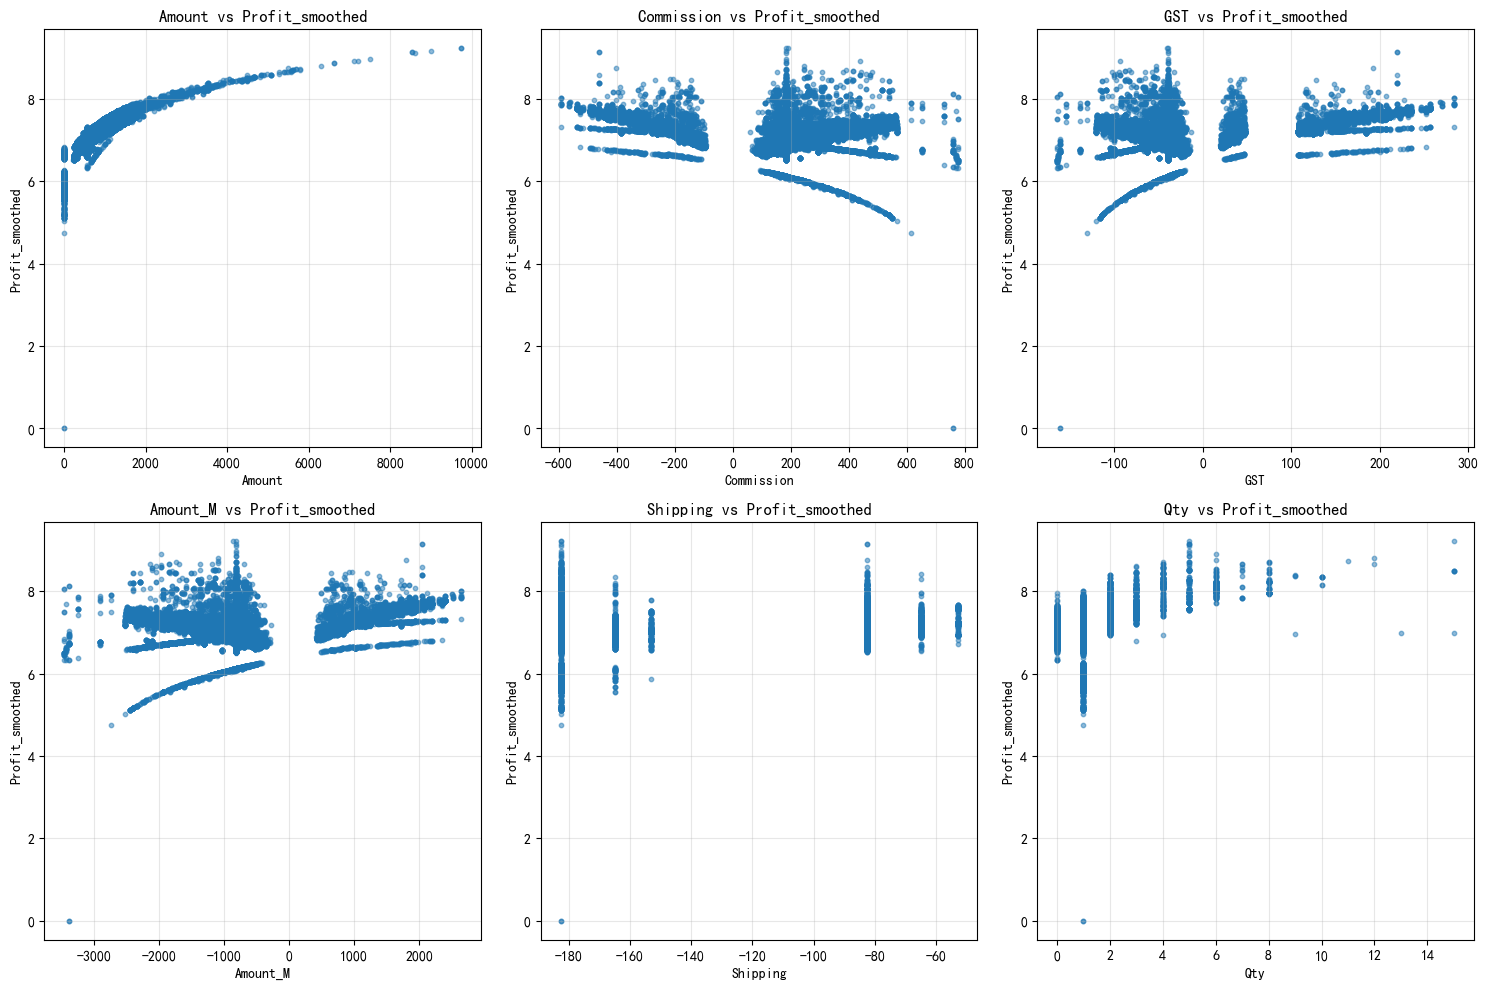

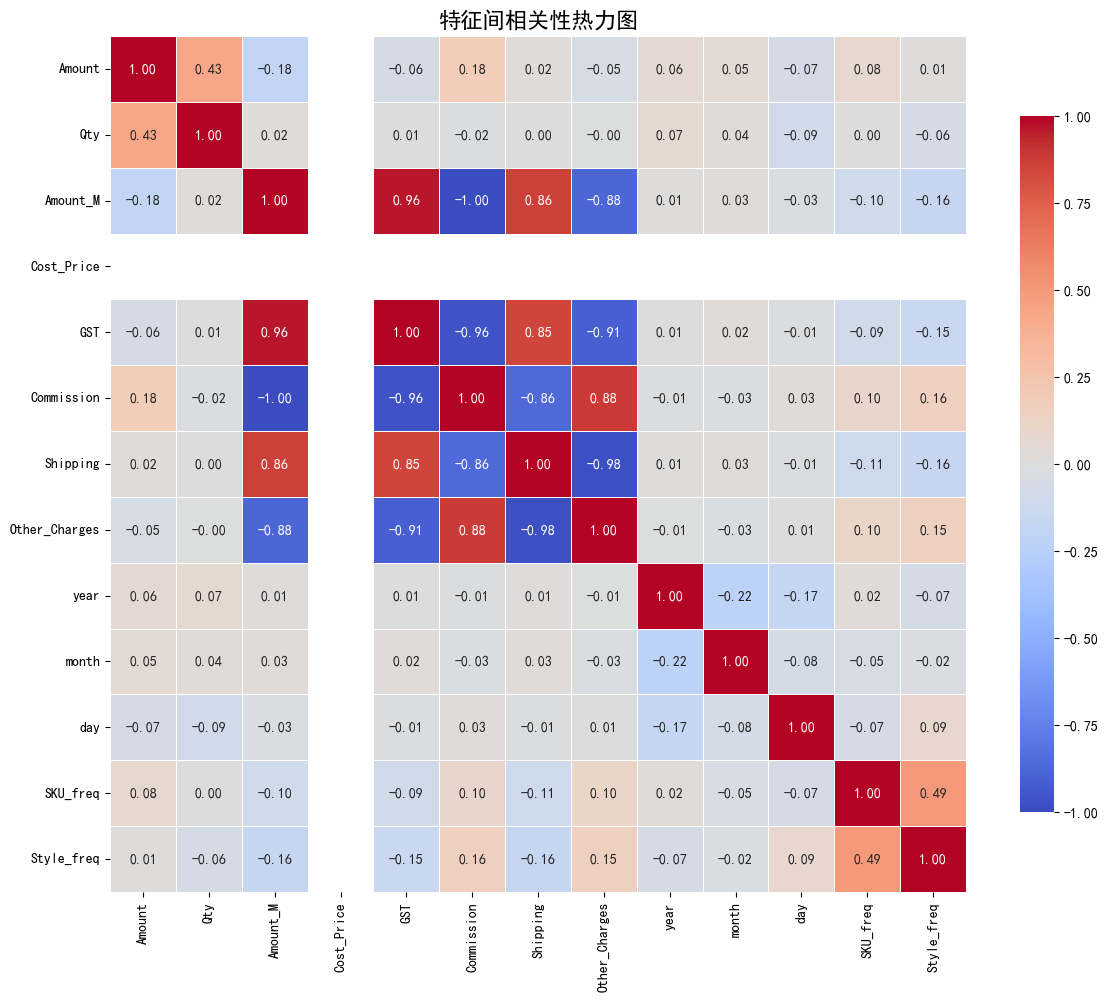

相关性最高的特征对：
GST            Amount_M         0.962164
Amount_M       GST              0.962164
Commission     Other_Charges    0.881204
Other_Charges  Commission       0.881204
Shipping       Amount_M         0.862469
Amount_M       Shipping         0.862469
GST            Shipping         0.847656
Shipping       GST              0.847656
Style_freq     SKU_freq         0.494234
SKU_freq       Style_freq       0.494234
dtype: float64


In [ ]:
import seaborn as sns

important_features = ['Amount', 'Commission', 'GST', 'Amount_M', 'Shipping', 'Qty', 'Other_Charges']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, feature in enumerate(important_features[:6]):
    if i < len(important_features):
        axes[i].scatter(X[feature], y, alpha=0.5, s=10)
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Profit_smoothed')
        axes[i].set_title(f'{feature} vs Profit_smoothed')
        axes[i].grid(True, alpha=0.3)

# 隐藏多余的子图
for i in range(len(important_features), 6):
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# 绘制特征之间的关联度图（相关性热力图）
plt.figure(figsize=(12, 10))

# 计算数值特征的相关性矩阵
numeric_features = X.select_dtypes(include=[np.number]).columns
correlation_matrix = X[numeric_features].corr()

# 绘制热力图
sns.heatmap(correlation_matrix, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm',
            center=0,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8})

plt.title('特征间相关性热力图', fontsize=16)
plt.tight_layout()
plt.show()

# 打印相关性最高的特征对
print("相关性最高的特征对：")
corr_pairs = correlation_matrix.unstack().sort_values(ascending=False)
# 去除自相关（值为1的）
corr_pairs = corr_pairs[corr_pairs < 0.99]
print(corr_pairs.head(10))


=== XGBoost 模型训练 ===
基础XGBoost 5折CV RMSE: 0.03203

=== 调优 max_depth ===
max_depth=3: RMSE=0.03992
max_depth=4: RMSE=0.03401
max_depth=5: RMSE=0.03220
max_depth=6: RMSE=0.03203
max_depth=7: RMSE=0.03040
max_depth=8: RMSE=0.03062
最佳 max_depth = 7

=== 调优 learning_rate ===
lr=0.01: RMSE=0.06259
lr=0.05: RMSE=0.02984
lr=0.10: RMSE=0.02975
lr=0.20: RMSE=0.02940
lr=0.30: RMSE=0.03044

=== GridSearchCV 综合调优 ===
最佳参数: {'colsample_bytree': 0.9, 'learning_rate': 0.15, 'max_depth': 6, 'subsample': 0.9}
最佳RMSE: 0.02961

=== 最终XGBoost模型 ===
最终XGBoost 5折CV RMSE: 0.02928

=== XGBoost 特征重要性 ===
 1. Amount              : 0.342113
 2. Other_Charges       : 0.315891
 3. Shipping            : 0.221741
 4. Commission          : 0.058086
 5. Amount_M            : 0.031971
 6. GST                 : 0.010085
 7. Qty                 : 0.005619
 8. source_International: 0.005132
 9. month               : 0.003146
10. SKU_freq            : 0.002679
11. Style_freq          : 0.002143
12. year                : 0.0

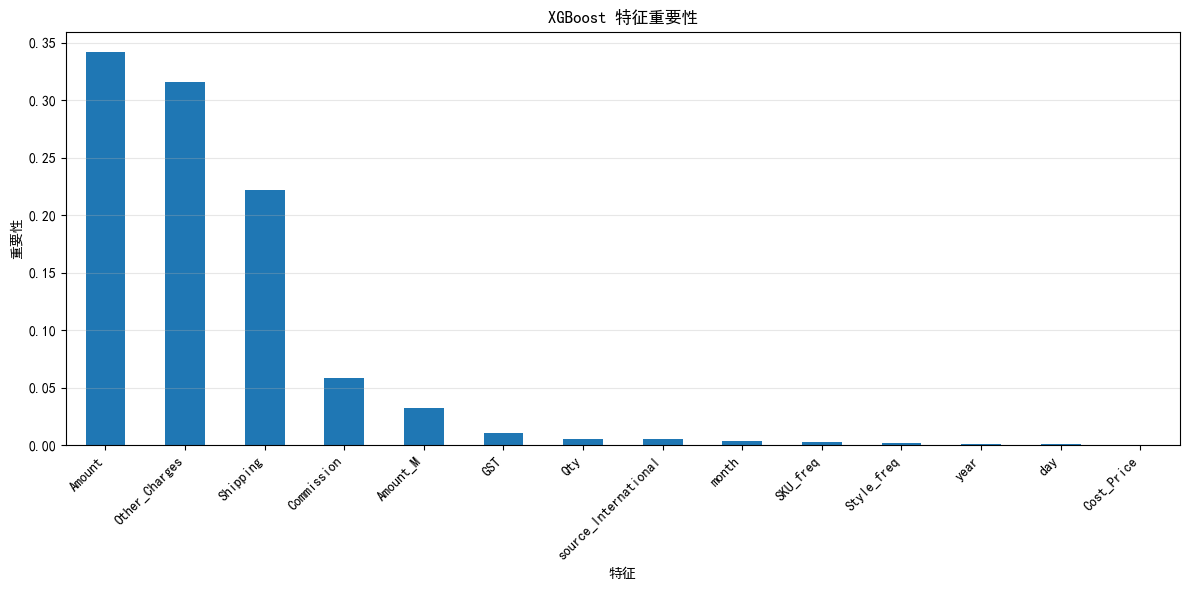

In [ ]:
# XGBoost模型
import xgboost as xgb
from sklearn.model_selection import cross_val_score, GridSearchCV

# 转换为DMatrix格式
dtrain = xgb.DMatrix(X, label=y)

# 初步参数搜索 - n_estimators
print("=== XGBoost 模型训练 ===")

# 基础模型
xgb_base = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

scores = cross_val_score(xgb_base, X, y, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
rmse_base = np.sqrt(-scores.mean())
print(f"基础XGBoost 5折CV RMSE: {rmse_base:.5f}")

# 调优 max_depth
print("\n=== 调优 max_depth ===")
depth_candidates = [3, 4, 5, 6, 7, 8]
cv_scores = []
for d in depth_candidates:
    model = xgb.XGBRegressor(
        n_estimators=100, learning_rate=0.1, max_depth=d,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
    )
    score = np.sqrt(-cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error', n_jobs=-1).mean())
    cv_scores.append(score)
    print(f"max_depth={d}: RMSE={score:.5f}")

best_depth = depth_candidates[np.argmin(cv_scores)]
print(f"最佳 max_depth = {best_depth}")

# 调优 learning_rate 与 n_estimators
print("\n=== 调优 learning_rate ===")
lr_candidates = [0.01, 0.05, 0.1, 0.2, 0.3]
for lr in lr_candidates:
    model = xgb.XGBRegressor(
        n_estimators=200, learning_rate=lr, max_depth=best_depth,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
    )
    score = np.sqrt(-cross_val_score(model, X, y, cv=5, scoring='neg_mean_squared_error', n_jobs=-1).mean())
    print(f"lr={lr:.2f}: RMSE={score:.5f}")

# GridSearchCV 综合调优
print("\n=== GridSearchCV 综合调优 ===")
param_grid = {
    'max_depth': [4, 5, 6],
    'learning_rate': [0.05, 0.1, 0.15],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9]
}

xgb_grid = xgb.XGBRegressor(n_estimators=100, random_state=42, n_jobs=-1)
grid = GridSearchCV(xgb_grid, param_grid, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(X, y)

print(f"最佳参数: {grid.best_params_}")
print(f"最佳RMSE: {np.sqrt(-grid.best_score_):.5f}")

# 最终模型
print("\n=== 最终XGBoost模型 ===")
best_params = grid.best_params_
final_xgb = xgb.XGBRegressor(
    n_estimators=200,
    **best_params,
    random_state=42,
    n_jobs=-1
)

final_scores = cross_val_score(final_xgb, X, y, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
final_rmse = np.sqrt(-final_scores.mean())
print(f"最终XGBoost 5折CV RMSE: {final_rmse:.5f}")

# 特征重要性
final_xgb.fit(X, y)
importances_xgb = pd.Series(final_xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\n=== XGBoost 特征重要性 ===")
for i, (feat, imp) in enumerate(importances_xgb.items()):
    print(f"{i+1:2d}. {feat:20s}: {imp:.6f}")

# 绘制特征重要性
plt.figure(figsize=(12, 6))
importances_xgb.plot(kind='bar')
plt.title('XGBoost 特征重要性')
plt.xlabel('特征')
plt.ylabel('重要性')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.grid(True, alpha=0.3, axis='y')
plt.show()


In [ ]:
# ========== 阶段五：最终模型训练（使用 early_stopping_rounds） ==========
print("\n" + "="*50)
print("阶段五：最终模型训练（early_stopping）")
print("="*50)

final_xgb = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=best_lr,
    max_depth=best_depth,
    min_child_weight=best_child,
    subsample=best_subsample,
    colsample_bytree=best_colsample,
    gamma=best_gamma,
    reg_alpha=best_alpha,
    reg_lambda=best_lambda,
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1,
    verbose=False
)

final_xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

best_iteration = final_xgb.best_iteration + 1
print(f"early_stopping 确定的最佳 n_estimators = {best_iteration}")

# 用确定的最佳 n_estimators 重新训练一个不带 early_stopping 的模型用于 CV 评估
final_xgb_cv = xgb.XGBRegressor(
    n_estimators=best_iteration,
    learning_rate=best_lr,
    max_depth=best_depth,
    min_child_weight=best_child,
    subsample=best_subsample,
    colsample_bytree=best_colsample,
    gamma=best_gamma,
    reg_alpha=best_alpha,
    reg_lambda=best_lambda,
    random_state=42,
    n_jobs=-1,
    verbose=False
)

# 最终评估（用不带 early_stopping 的版本做 CV）
from sklearn.model_selection import cross_val_score
final_scores = cross_val_score(
    final_xgb_cv, X, y, cv=5,
    scoring='neg_mean_squared_error', n_jobs=-1
)
final_rmse = np.sqrt(-final_scores.mean())
print(f"最终XGBoost 5折CV RMSE: {final_rmse:.5f}")

# 训练集 vs 验证集误差（过拟合检查）
train_pred = final_xgb.predict(X_train)
val_pred = final_xgb.predict(X_val)
train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
print(f"训练集 RMSE: {train_rmse:.5f}")
print(f"验证集 RMSE: {val_rmse:.5f}")

if val_rmse > train_rmse * 1.1:
    print("⚠️ 存在过拟合，可进一步增大 min_child_weight 或 reg_lambda")
else:
    print("✅ 泛化良好")



阶段五：最终模型训练（early_stopping）


NameError: name 'best_lr' is not defined

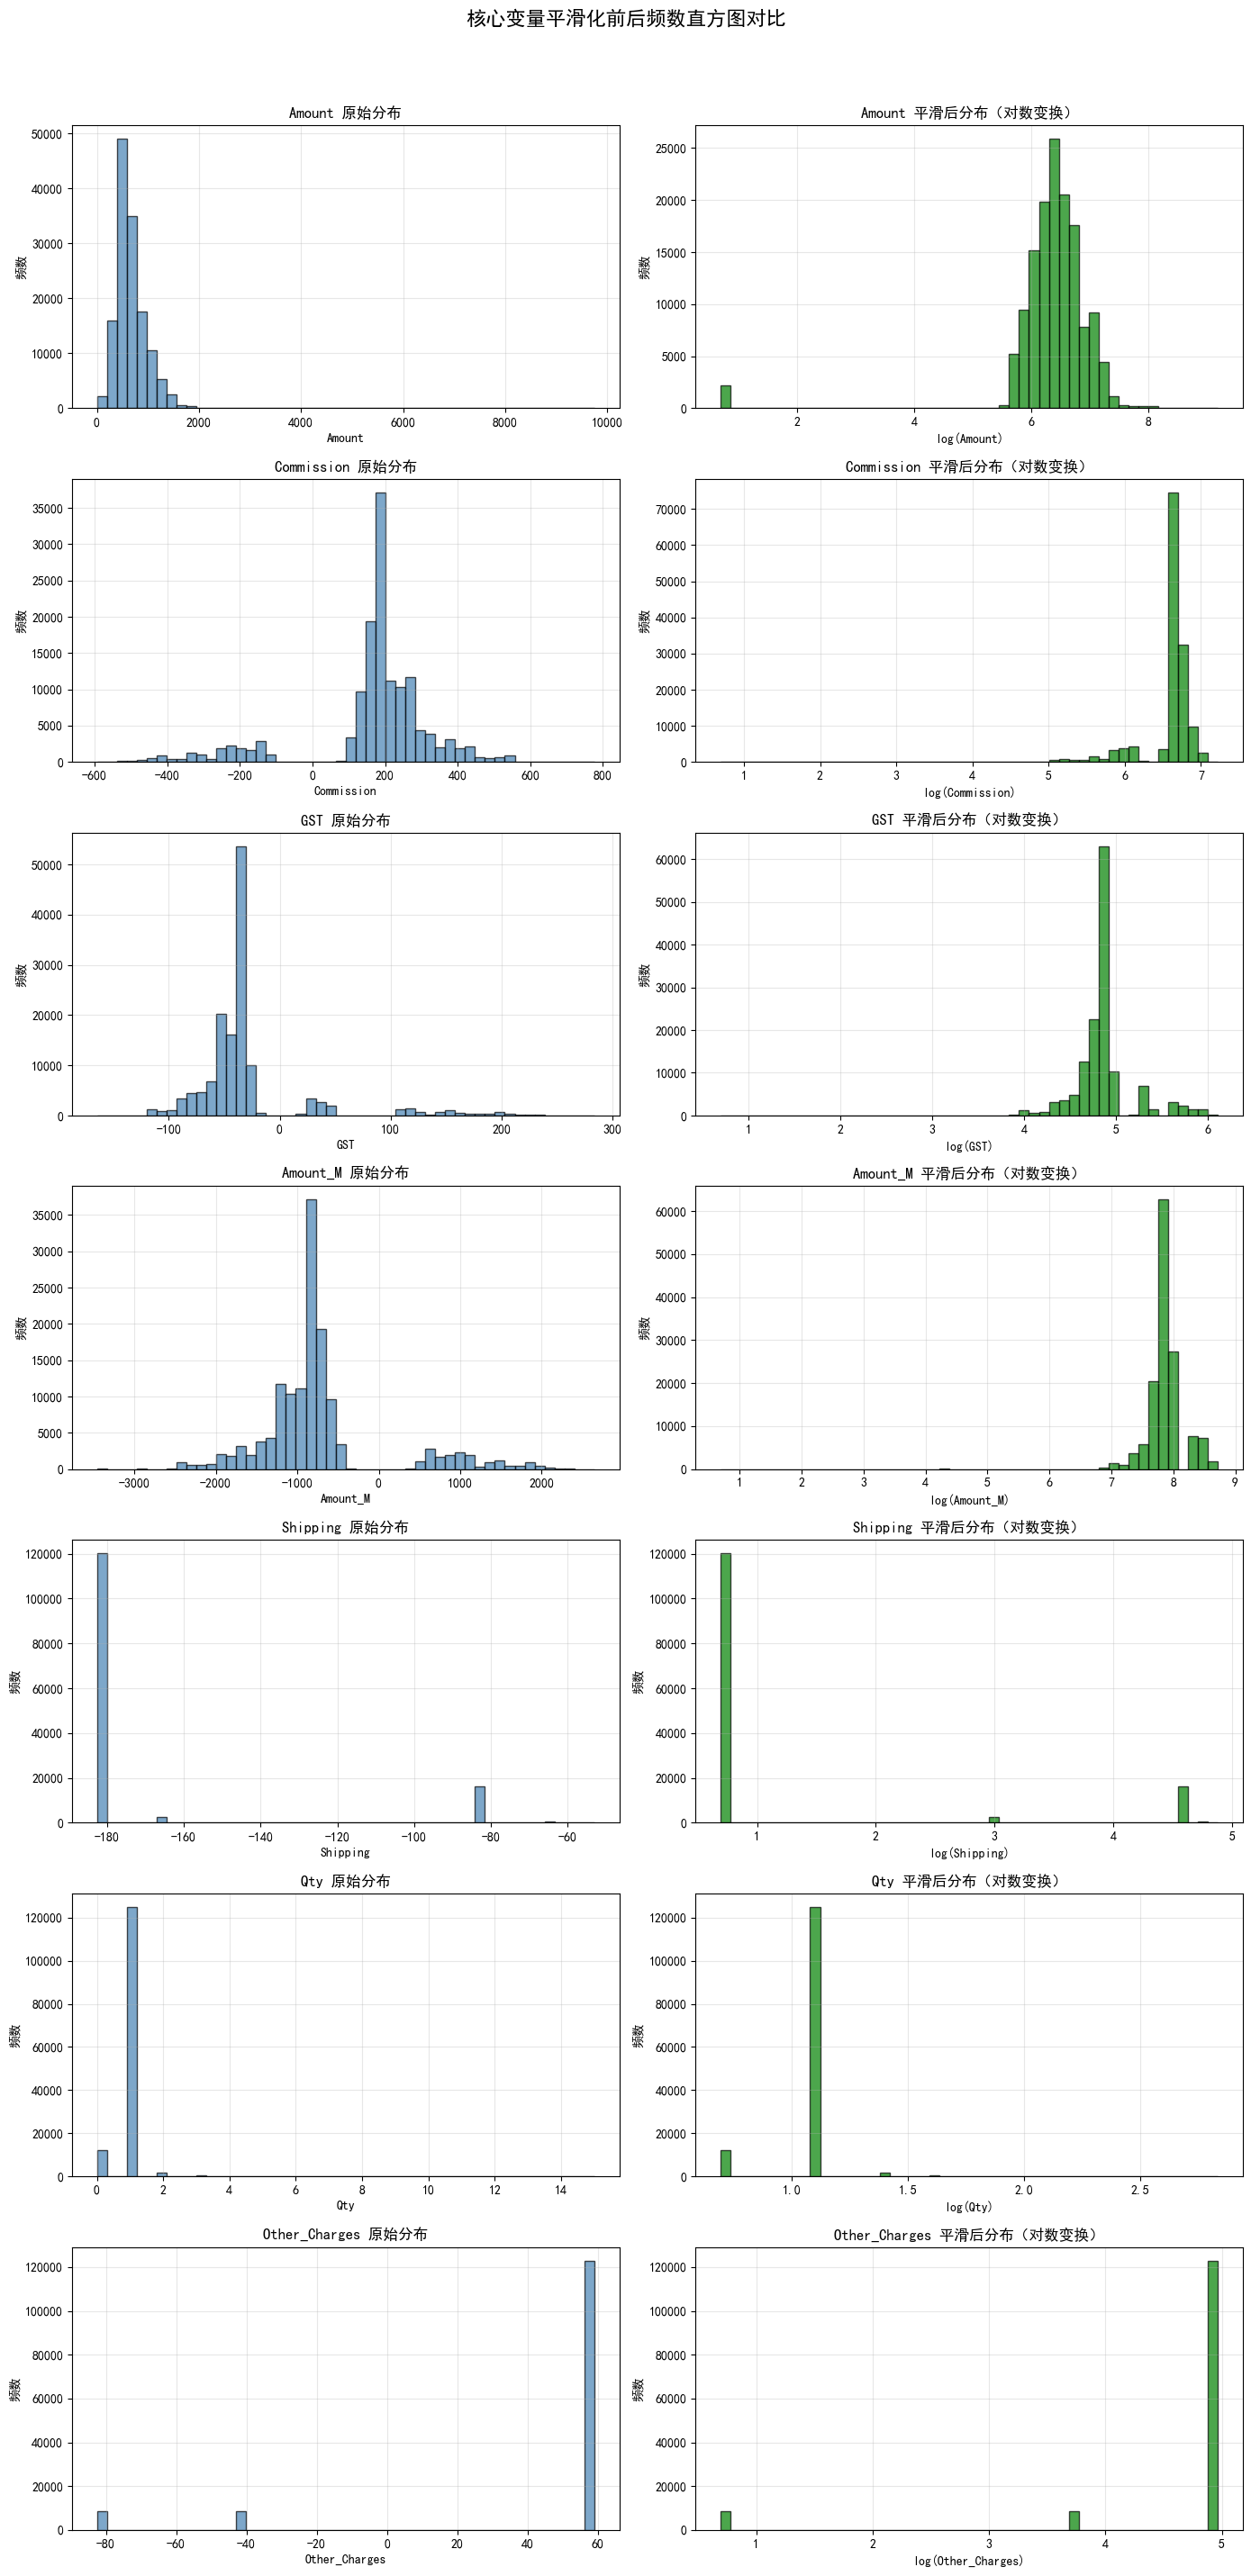

In [ ]:
# 设置中文字体，防止乱码
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 选择核心数值特征
core_features = ['Amount', 'Commission', 'GST', 'Amount_M', 'Shipping', 'Qty', 'Other_Charges']
existing_features = [f for f in core_features if f in X.columns]

n_features = len(existing_features)
fig, axes = plt.subplots(n_features, 2, figsize=(14, 4 * n_features))

for i, feat in enumerate(existing_features):
    # 原始分布
    axes[i, 0].hist(X[feat].dropna(), bins=50, edgecolor='black', alpha=0.7, color='steelblue')
    axes[i, 0].set_title(f'{feat} 原始分布', fontsize=12)
    axes[i, 0].set_xlabel(feat)
    axes[i, 0].set_ylabel('频数')
    axes[i, 0].grid(True, alpha=0.3)
    
    # 平滑后分布（对数变换）
    min_val = X[feat].min()
    if min_val <= 0:
        shift_val = 1 - min_val
        smoothed_feat = np.log1p(X[feat] + shift_val)
    else:
        smoothed_feat = np.log1p(X[feat])
    
    axes[i, 1].hist(smoothed_feat.dropna(), bins=50, edgecolor='black', alpha=0.7, color='green')
    axes[i, 1].set_title(f'{feat} 平滑后分布（对数变换）', fontsize=12)
    axes[i, 1].set_xlabel(f'log({feat})')
    axes[i, 1].set_ylabel('频数')
    axes[i, 1].grid(True, alpha=0.3)

plt.suptitle('核心变量平滑化前后频数直方图对比', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


In [ ]:
X['Shipping'].unique()

array([-182.6, -164.9, -153.1,  -82.6,  -53.1,  -64.9])